In [ ]:
%pip install mrmr-selection

In [ ]:
# Import neccessary libraries
import itertools

import pandas as pd
import numpy as np

# For graph plot
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns

# For feature scaling and selection
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, MaxAbsScaler
from sklearn.feature_selection import mutual_info_regression, SequentialFeatureSelector
from sklearn.svm import SVR
from mrmr import mrmr_regression

# For DLNM model
from statsmodels.gam.gam_cross_validation.cross_validators import KFold
import statsmodels.api as sm
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines
from statsmodels.gam.api import GLMGam, BSplines, CyclicCubicSplines
from statsmodels.gam.gam_cross_validation.gam_cross_validation import MultivariateGAMCVPath
from statsmodels.genmod.families.family import Tweedie
from statsmodels.genmod.families.links import log
from statsmodels.gam.smooth_basis import GenericSmoothers
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from pydlnm.utils import logknots
from dlnm import crossbasis, plot_crosspred, cb_pen


In [ ]:
# Function for constructing the CrossBasis matrix
def crossbasis_construct(dataframe, col_lst, max_lag, setting_lst): 
    # setting_lst include the values for the degree and degree of freedom (df) for both exposure and lag dimension in order
    
    # Initlialize the list to place cross basis matrices
    cb_list = []

    # Construct cross basis for each exposure variables
    for col in col_lst:
        knots_var = np.quantile(dataframe[col].dropna(), [0.1, 0.75, 0.9])
        lag_knots = logknots([0, max_lag], nk=setting_lst[3])

        tmp_cb = CrossBasis(dataframe[col].values, lag=max_lag, 
                                argvar={"fun": "bs", "degree": setting_lst[0], "df": setting_lst[1]}, 
                                arglag={"fun": "bs", "degree": setting_lst[2], "df": setting_lst[3]})
        cb_list.append(tmp_cb)

    X_exposure = np.concat(cb_list, axis=1)

    # Construct the DataFrame object for later model construction 
    model_data = np.concat([dataframe.drop(columns=["From"]).to_numpy(), X_exposure], axis=1)
    model_data = pd.DataFrame(model_data)

    # Rename the columns of the mode_data DataFrame 
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(tmp_cb.shape[1])]
    model_data.columns = [n for n in dataframe.columns if n!="From"] + exp_name_list

    # Fill in 0 for the missing value(s)
    model_data[exp_name_list] = model_data[exp_name_list].fillna(0)

    # Return the variables that need to be used 
    return model_data, exp_name_list, cb_list

In [ ]:
# Function for constructing the smoothers 
def smoothers_construct(dataframe, bs_dict, cs_dict):
    # bs_dict and cs_dict contains the name, degree and df for the spline function constructions needed 
    
    # Use B spline for 'Year'
    bs = UnivariateBSplines(dataframe[bs_dict["name"]], df=bs_dict["df"], degree=bs_dict["degree"], include_intercept=False, variable_name=bs_dict["name"])
    # Use Cubic Cyclic Spline for 'Week'
    cs = UnivariateCubicCyclicSplines(dataframe[cs_dict["name"]], df=cs_dict["df"], constraints="center", variable_name=cs_dict["name"])

    # Group the two spline functions together to form a single smoother variable
    sm_weights = [bs, cs]
    X_smooth = dataframe[bs_dict["name"]+[cs_dict["name"]]]
    smoothers = GenericSmoothers(X_smooth, sm_weights)

    # Return the smoother variable
    return smoothers

In [ ]:
# Function for constructing GAM model with Negative Binomial family 
def NB_GAM_model(dataframe, tar_var, exp_names, smoothers, a): 
    # Initializa the formula
    formula = f"{tar_var} ~ {exp_names}"

    # Build and fit the model
    NegativeBinomial_gam_model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=a, family=sm.families.NegativeBinomial(alpha=0.5))
    result = NegativeBinomial_gam_model.fit()
    # result = NegativeBinomial_gam_model.fit_regularized(method="l1_slsqp", alpha=1.0)
        # no penalization for Negative Binomial

    # Return the model and the result 
    return NegativeBinomial_gam_model, result

In [ ]:
# to-do (incomplete / not used)
# Function for constructing GAM model with Tweddie family
def Tweddie_GAM_model(dataframe, tar_var, exp_names, smoothers, a):
    # Initialize the formula 
    formula = f"{tar_var} ~ {exp_names}"

    # Build and fit the model
    Tweddie_gam_model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=a, family=Tweedie(link=log(), var_power=1.5))
    result = Tweddie_gam_model.fit()
    
    # Return the model and the result 
    return Tweddie_gam_model, result

In [ ]:
# Function for 
def pred_cal(result, dataframe, cb_lst, mete_lst, i):
    n_cb_cols = cb_lst[i].shape[1]
    start_idx = 0
    end_idx = start_idx+n_cb_cols
    cb_coef = result.params.values[start_idx:end_idx]
    cb_vcov = result.cov_params().iloc[start_idx:end_idx, start_idx:end_idx]
    at = np.linspace(dataframe[mete_lst[i]].min(), dataframe[mete_lst[i]].max(), 100)
    cen = dataframe[mete_lst[i]].median()
    pred = crosspred(basis=cb_lst[i], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)
    
    print(f"{mete_lst[i]} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")

    return pred

In [ ]:
# Function for plotting the 3D graph 
def graph_3Dplot(pred, exp):
    fig = plot_crosspred(pred, ptype="3d")

    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel(exp, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Residual Risk (RR)", labelpad=10)
    ax.set_yticks(np.linspace(0, 4, pred.matRRfit.shape[1]))

    plt.tight_layout()
    plt.show()

In [ ]:
# Function for plotting the exposure-response slice plot
def graph_expresponseplot(pred, exp):
    fig = plot_crosspred(pred, ptype="overall")
    cen = df[exp].median()

    ax = fig.gca()

    ax.axvline(x=cen, color='black', linestyle=':', linewidth=1.2, label=f'Centering Temp ({cen:.1f}°C)')
    ax.set_title('Overall Cumulative Exposure-Response Association', fontsize=14, pad=15)
    ax.set_xlabel(exp, fontsize=12)
    ax.legend(loc="best", frameon=True)

    plt.show()

In [ ]:
# Function for plotting the lag-response slice plot
def graph_lagresponseplot(pred, target_var):
    fig = plot_crosspred(
        pred, 
        ptype="slices", 
        var=target_var
    )

    ax = fig.gca()

    ax.set_title(f"Lag-Response Curve at {target_var}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color='gray', linestyle='--', alpha=0.7) # Add baseline at RR=1
    
    plt.show()

In [ ]:
# Function for all the three plots at the same time 
def graph_plot(pred, exp, val):
    graph_3Dplot(pred, exp)
    graph_expresponseplot(pred, exp)
    graph_lagresponseplot(pred, val)

In [51]:
def alpha_byAIC(dataframe, tar_var, exp_names, smoothers, alpha):
    best_a = 0
    best_aic = np.inf

    for a1, a2 in itertools.product(alpha, alpha):
        model, result = NB_GAM_model(dataframe, tar_var, exp_names, smoothers, [a1, a2])
        print(f"alpha {[a1, a2]} with AIC value {result.aic}")
        if result.aic < best_aic:
            best_aic = result.aic
            best_a = [a1, a2]

    return best_a

In [52]:
def alpha_byGCV(dataframe, tar_var, exp_names, smoothers):
    model, result = NB_GAM_model(dataframe, tar_var, exp_names, smoothers, [100, 500])
    best_a = model.select_penweight(criterion="gcv")
    return best_a[0]

In [68]:
def cb_setting_performance(dataframe, exp_col, setting_options):
    best_setting_idx = 0
    performance = []
    for set in setting_options:
        model_data, exp_names, cb_list = crossbasis_construct(dataframe, exp_col, 4, set)
        smoothers = smoothers_construct(df, {"name": "Year", "degree": 2, "df": 3}, {"name": "Week", "df": 4})
        initial_alpha = [1.0, 1.0]
        model, result = NB_GAM_model(model_data, "H1", exp_names, smoothers, initial_alpha)
        print(f"AIC value for the settings {set}: {result.aic}")
        performance.append([result.aic, result.deviance, result.null_deviance, result.df_resid, result.df_model])

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_setting_idx][0]:
            best_setting_idx = i

    return setting_options[best_setting_idx]


In [ ]:
# Function for feature scaling (uses standardlization)
def feature_scaling():
    df[mete_col] = StandardScaler().fit_transform(df[mete_col])
    df["Year"] = df["Year"] - df["Year"].mean()
  

In [ ]:
def feature_selection_MI(dataframe, exp_col, outcome_col):
    X = dataframe[exp_col]
    Y = dataframe[outcome_col]
    
    # Calculate mutual information for regression
    mi_scores = mutual_info_regression(X, Y)
    
    # Display scores
    mi_df = pd.DataFrame({'Feature': [col for col in X], 'MI_Score': mi_scores})
    selected_features = mi_df.loc[mi_df["MI_Score"]>=0, "Feature"].to_list()

    return mi_df.sort_values(by='MI_Score', ascending=False), selected_features

In [56]:
def feature_selection_MRMR(dataframe, exp_col, outcome_col):
    selected_features = mrmr_regression(X=dataframe[exp_col], y=dataframe[outcome_col], K=5)
    print("Selected Features:", selected_features)
            
    return selected_features 

---

In [107]:
# Import data and basic settings
df = pd.read_csv("data.csv")

df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB"]

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]

df["From"] = pd.to_datetime(df["From"])


In [ ]:

url = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"

df_owid = pd.read_csv(url)

country_code = "HKG"
df_country = df_owid[df_owid["iso_code"] == country_code].copy()

df_country["date"] = pd.to_datetime(df_country["date"])

df_stringency = df_country[["date", "stringency_index"]].copy()


             date  stringency_index
169603 2022-12-22             42.28
169604 2022-12-23             42.28
169605 2022-12-24             42.28
169606 2022-12-25             42.28
169607 2022-12-26             42.28
169608 2022-12-27             42.28
169609 2022-12-28             42.28
169610 2022-12-29             11.11
169611 2022-12-30             11.11
169612 2022-12-31             11.11


In [92]:
df_stringency

,date,stringency_index
168547,2020-01-31,49.07
168548,2020-02-01,49.07
168549,2020-02-02,49.07
168550,2020-02-03,49.07
168551,2020-02-04,49.07
...,...,...
170196,2024-08-06,NaN
170197,2024-08-07,NaN
170198,2024-08-08,NaN
170199,2024-08-09,NaN


In [ ]:
df = pd.merge(df, df_stringency, left_on="From", right_on="date", how="left")
df["stringency_index"] = df["stringency_index"].fillna(0.0)

df.drop(columns="date", inplace=True)

covid_index = df[((df["From"] >= "2020-01-03") & (df["From"] <= "2023-03-01"))].index
df.loc[covid_index, "pandemic_flag"] = 1
df["pandemic_flag"].fillna(0)

,Year,Week,From,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,date,stringency_index
0,2002,36,2002-09-01,14.3,28.15,76.5,19.66,1008.20,23.2,7.35,4.0,1,12,3.0,19,NaT,0.0
1,2002,37,2002-09-08,13.6,26.70,85.0,9.35,1006.30,23.8,10.50,3.0,0,6,4.0,15,NaT,0.0
2,2002,38,2002-09-15,11.2,26.40,83.0,16.75,1011.35,23.2,13.45,4.0,0,4,4.0,13,NaT,0.0


,Year,Week,From,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,date,stringency_index
1250,2026,33,2026-08-16,7.9,29.7,82.0,13.81,1003.1,26.00,9.5,3.0,735,245,65.0,1077,NaT,0.0
1251,2026,34,2026-08-23,6.7,29.9,80.0,14.01,1001.6,26.70,8.3,3.0,846,206,60.0,1148,NaT,0.0
1252,2026,35,2026-08-30,3.9,28.4,84.5,8.44,998.9,25.95,6.0,2.0,1088,181,55.0,1367,NaT,0.0


,Year,Week,From,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,date,stringency_index
1067,2023,7,2023-02-12,20.8,18.1,70.0,13.62,1019.25,12.80,10.2,2.0,6,48,6.0,60,2023-02-12,0.0
1068,2023,8,2023-02-19,21.0,17.6,67.0,19.76,1019.30,11.60,11.4,3.0,7,19,6.0,32,2023-02-19,0.0
1069,2023,9,2023-02-26,20.4,17.7,67.0,21.10,1024.40,11.35,11.3,3.0,19,14,1.0,34,2023-02-26,0.0


In [58]:
# Feature scaling and selection
np.random.seed(42)

feature_scaling()
feature_selection_MI(df, mete_col, "H1")
mete_col = feature_selection_MRMR(df, mete_col, "H1")

100%|██████████| 5/5 [00:04<00:00,  1.09it/s]

Selected Features: ['UV', 'RH', 'WS', 'temp', 'SR']


In [59]:
initial_alpha = [1.0, 1.0]
initial_cb_setting = [2, 5, 3, 5]

In [ ]:
model_data, exp_name_list, cb_list = crossbasis_construct(df, mete_col, 4, initial_cb_setting)


In [ ]:
train_end = int(model_data.shape[0] * 0.6)
validation_end = int(model_data.shape[0] * 0.8)

train_data = model_data.iloc[:train_end]
validation_data = model_data.iloc[train_end:validation_end]
test_data = model_data.iloc[validation_end:]


In [ ]:
#old : smoothers = smoothers_construct(df, {"name": "Year", "degree": 2, "df": 3}, {"name": "Week", "df": 4})
smoothers = smoothers_construct(df, {"name": ["Year", "stringency_index"], "degree": [2, 3], "df": [3, 3]}, {"name": "Week", "df": 4})

model, result = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, initial_alpha)


In [69]:
setting_options = [
    [2, 5, 3, 5], 
    [2, 4, 3, 5], 
    [2, 3, 3, 5], 
    [2, 5, 2, 4],
    [2, 4, 2, 4]
]

best_cb_setting = cb_setting_performance(df, mete_col, setting_options)
print(f"The best CrossBasis settings [degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension]: \n{best_cb_setting}")

AIC value for the settings [2, 5, 3, 5]: 13824.073650774442
AIC value for the settings [2, 4, 3, 5]: 13855.876942577994
AIC value for the settings [2, 3, 3, 5]: 13831.184475218086
AIC value for the settings [2, 5, 2, 4]: 13602.11398156922
AIC value for the settings [2, 4, 2, 4]: 13752.549059752144
The best CrossBasis settings [degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension]: 
[2, 5, 2, 4]


In [ ]:
smoothers = smoothers_construct(df, {"name": "Year", "degree": 2, "df": 3}, {"name": "Week", "df": 4})

In [ ]:
alpha_choice = [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]
best_a_aic = alpha_byAIC(model_data, "H1", " + ".join(exp_name_list), smoothers, alpha_choice)

print(f"alpha {best_a_aic} is the best tested with AIC")

alpha [0.01, 0.01] with AIC value 14661.647525055321
alpha [0.01, 0.1] with AIC value 14661.647469220929
alpha [0.01, 1.0] with AIC value 14661.646915997322
alpha [0.01, 10.0] with AIC value 14661.641805078798
alpha [0.01, 50.0] with AIC value 14661.62835964347
alpha [0.01, 100.0] with AIC value 14661.632072920896
alpha [0.1, 0.01] with AIC value 14661.647517549167
alpha [0.1, 0.1] with AIC value 14661.647461714912
alpha [0.1, 1.0] with AIC value 14661.646908492616
alpha [0.1, 10.0] with AIC value 14661.641797589045
alpha [0.1, 50.0] with AIC value 14661.628352219483
alpha [0.1, 100.0] with AIC value 14661.632065576774
alpha [1.0, 0.01] with AIC value 14661.647442502288
alpha [1.0, 0.1] with AIC value 14661.647387280555
alpha [1.0, 1.0] with AIC value 14661.646833460018
alpha [1.0, 10.0] with AIC value 14661.641722706167
alpha [1.0, 50.0] with AIC value 14661.628277995576
alpha [1.0, 100.0] with AIC value 14661.631992150076
alpha [10.0, 0.01] with AIC value 14661.646694451498
alpha [10

In [ ]:
model, result = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_aic)
print(result.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                  1148.71
Model Family:        NegativeBinomial   Df Model:                       103.29
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -6695.7
Date:                Tue, 10 Nov 2026   Deviance:                       7234.5
Time:                        11:02:30   Pearson chi2:                 7.66e+03
No. Iterations:                  1000   Pseudo R-squ. (CS):             0.9668
Covariance Type:            nonrobust                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         3.3656      0.493      6.827

In [587]:
best_a_gcv = alpha_byGCV(df, "H1", " + ".join(mete_col), smoothers)

print(f"alpha {best_a_gcv} is the best tested with GCV")


alpha [1.40878725e+43 6.69160853e+04] is the best tested with GCV


In [589]:
model, result = NB_GAM_model(df, "H1", " + ".join(mete_col), smoothers, best_a_gcv)
print(result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                     1253
Model Family:        NegativeBinomial   Df Model:                           -1
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -94235.
Date:                Mon, 09 Nov 2026   Deviance:                   1.8231e+05
Time:                        09:04:01   Pearson chi2:                 3.38e+07
No. Iterations:                     3   Pseudo R-squ. (CS):         -1.600e+59
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   9.979e-35   5.34e-29   1.87e-06      1.0

UV RR range: 0.677 to 57.169


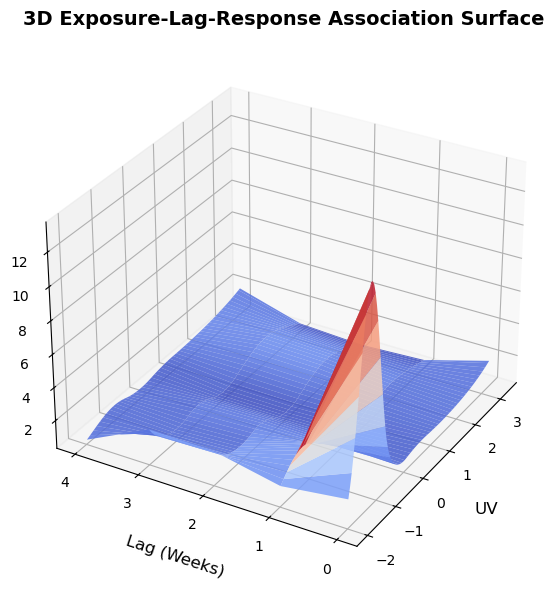

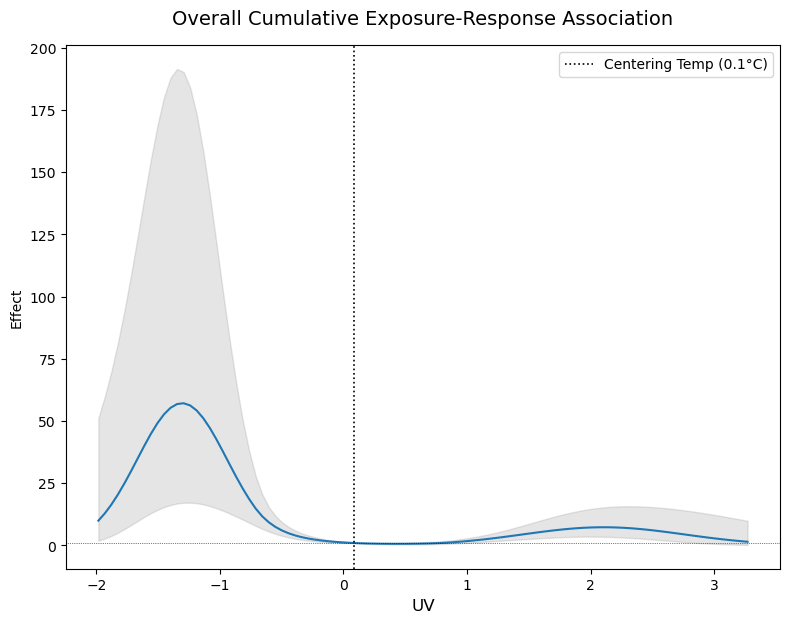

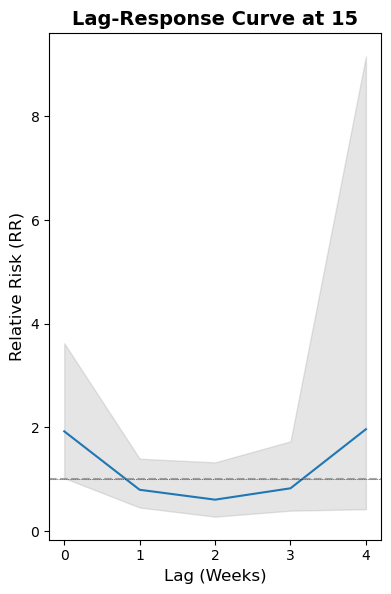

In [ ]:
pred = pred_cal(result, model_data, cb_list, mete_col, 0)
graph_plot(pred, mete_col[0], 15)